In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
import scipy.stats as stats
import numpy as np

%matplotlib inline

In [2]:
df = pd.read_csv(r"C:\Users\Usuario\Documents\Ironhack\Week5\Day2\lab-eda-bivariate\amz_uk_price_prediction_dataset.csv")

In [3]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


In [4]:
# ---- Part 1: Analyzing Best-Seller Trends Across Product Categories ---- #


# Crosstab Analysis:

# 1. Create a crosstab between the product category and the isBestSeller status.

category_bestseller_ct = pd.crosstab(df['category'], df['isBestSeller'])

category_bestseller_ct.columns = ['Not_Best_Seller', 'Best_Seller']


In [5]:
# Hint: one option is to calculate the proportion of best-sellers for each category and then sort the categories based on this proportion in descending order

category_bestseller_ct['proportion'] = (category_bestseller_ct['Best_Seller'] / 
                                        (category_bestseller_ct['Best_Seller'] + category_bestseller_ct['Not_Best_Seller']))

In [6]:
# Are there categories where being a best-seller is more prevalent?

top_10_plot = category_bestseller_ct.sort_values(by='proportion', ascending=False).head(10)
plot_data = top_10_plot[['Not_Best_Seller', 'Best_Seller']]

print(top_10_plot)


                                Not_Best_Seller  Best_Seller  proportion
category                                                                
Grocery                                    9008          556    0.058135
Smart Home Security & Lighting               98            6    0.057692
Health & Personal Care                     9017          552    0.057686
Mobile Phone Accessories                    248           11    0.042471
Power & Hand Tools                         8353          306    0.035339
Billiard, Snooker & Pool                    241            8    0.032129
Pet Supplies                               9152          285    0.030200
Home Brewing & Wine Making                  239            7    0.028455
Wind Instruments                            243            7    0.028000
Mirrors                                     243            7    0.028000


In [7]:
# 2. Statistical Tests:
# Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.

chi2, p, dof, expected = chi2_contingency(pd.crosstab(df['category'], df['isBestSeller']))

print(f"Chi-Square Statistic: {chi2}")
print(f"P-value: {p}")


Chi-Square Statistic: 36540.20270061387
P-value: 0.0


In [8]:
# Compute Cramér's V to understand the strength of association between best-seller status and category.

n = len(df)
phi2 = chi2 / n
r, k = pd.crosstab(df['category'], df['isBestSeller']).shape
phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
rcorr = r - ((r-1)**2)/(n-1)
kcorr = k - ((k-1)**2)/(n-1)
cramers_v = np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

print(f"Cramér's V: {cramers_v}")

Cramér's V: 0.12178835496344273


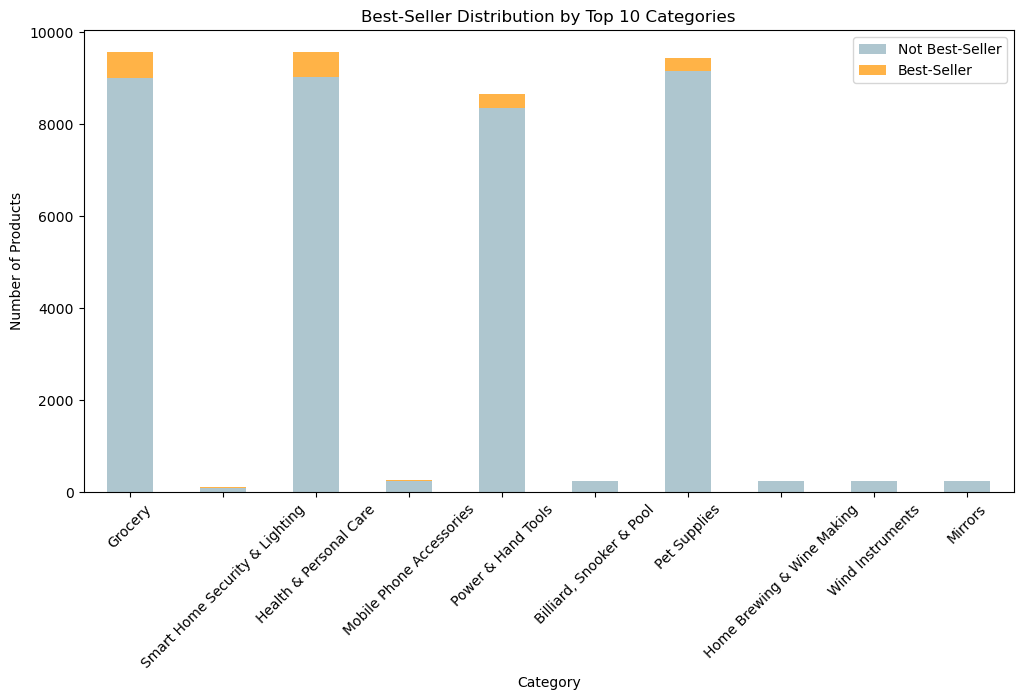

In [9]:
# 3. Visualizations:
# Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

plot_data.plot(kind='bar', stacked=True, figsize=(12, 6), color=['#aec6cf', '#ffb347'])

plt.title('Best-Seller Distribution by Top 10 Categories')
plt.xlabel('Category')
plt.ylabel('Number of Products')
plt.legend(['Not Best-Seller', 'Best-Seller'], loc='upper right')
plt.xticks(rotation=45)
plt.show()

In [13]:
# ---- Part 2: Exploring Product Prices and Ratings Across Categories and Brands ---- #

# 0. Preliminary Step: Remove outliers in product prices.
# For this purpose, we can use the IQR (Interquartile Range) method. 

Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Define Bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR


df_clean = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print(f"With Outliers: {df.shape}")
print(f"Without Outliers: {df_clean.shape}")

With Outliers: (2443651, 9)
Without Outliers: (2115963, 9)


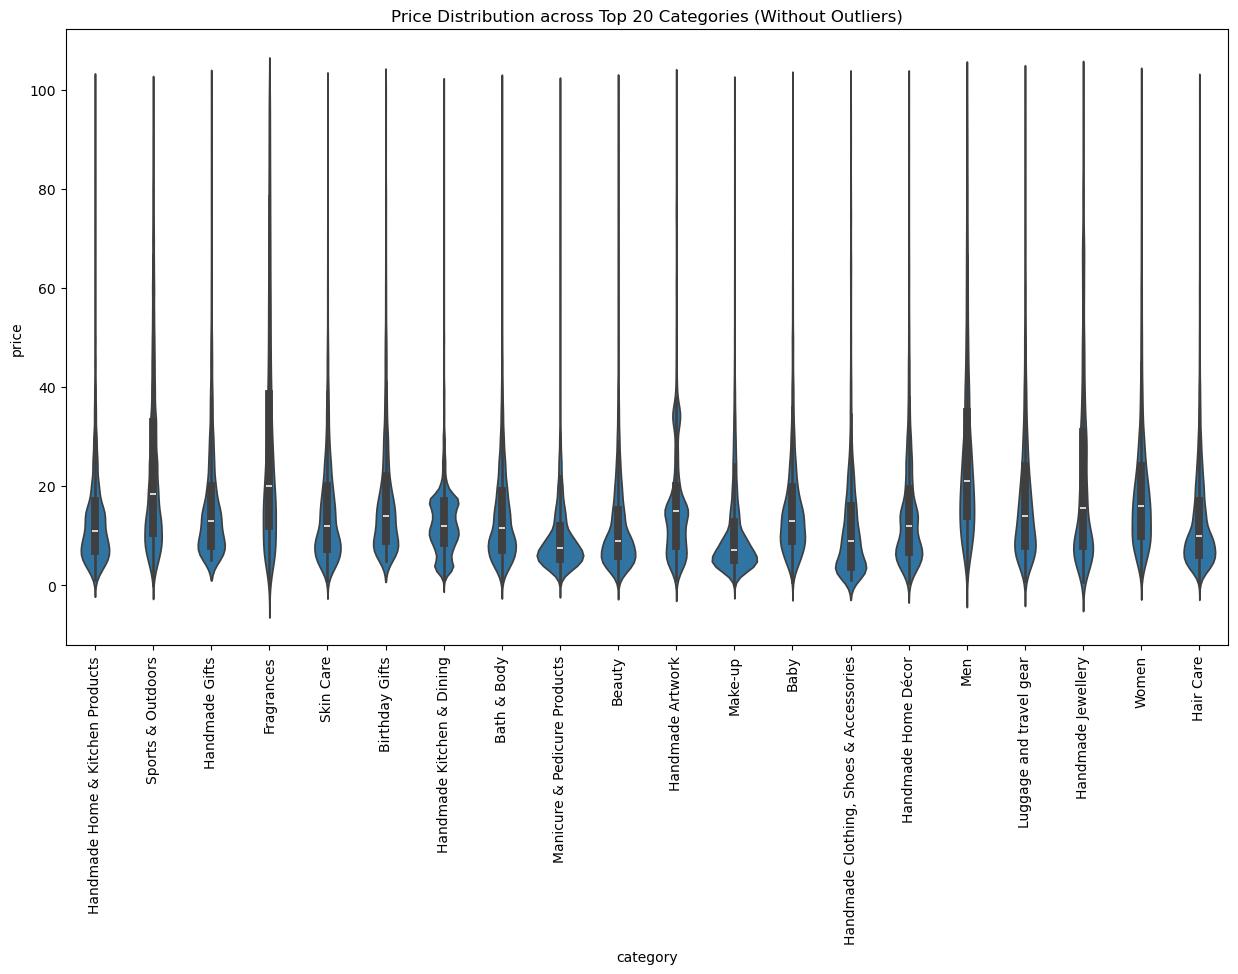

-------
Question: Which product category tends to have the highest median price? Don't filter here by top categories.
Category with highest median price: Desktop PCs


In [18]:
# 1. Violin Plots:
# Use a violin plot to visualize the distribution of price across different product categories. Filter out the top 20 categories based on count for better visualization.


# Filter for top 20 categories by count
top_20_cats = df_clean['category'].value_counts().nlargest(20).index
df_top_20 = df_clean[df_clean['category'].isin(top_20_cats)]

plt.figure(figsize=(15, 8))
sns.violinplot(x='category', y='price', data=df_top_20)
plt.xticks(rotation=90)
plt.title('Price Distribution across Top 20 Categories (Without Outliers)')
plt.show()

print("-------")
print("Question: Which product category tends to have the highest median price? Don't filter here by top categories.")
median_prices = df_clean.groupby('category')['price'].median().sort_values(ascending=False)
print(f"Category with highest median price: {median_prices.index[0]}")



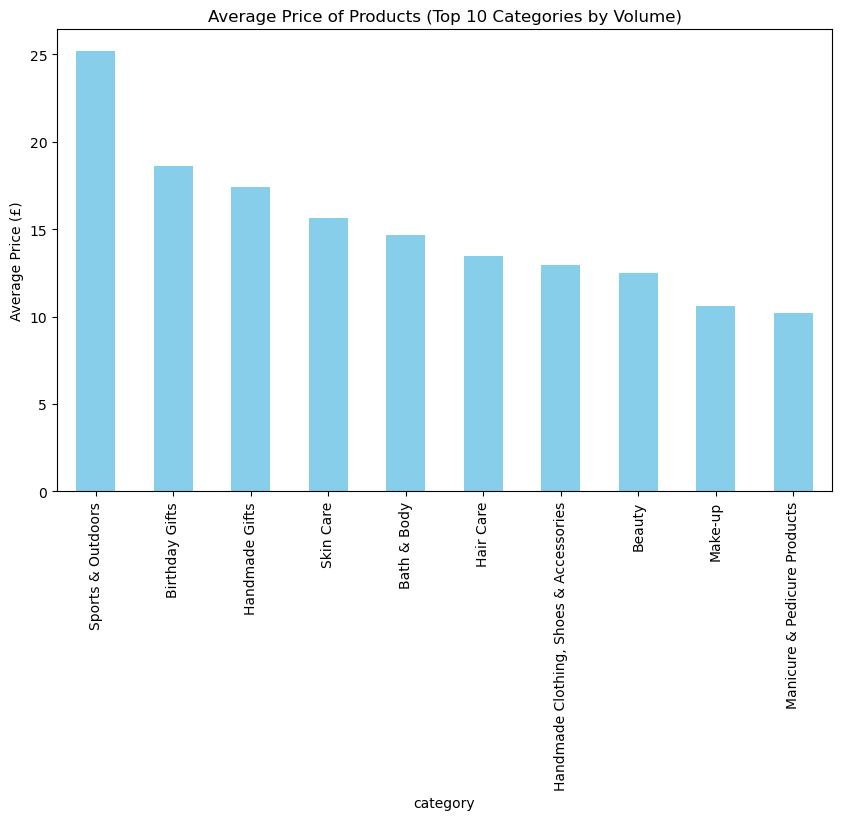

-------
Question: Which product category commands the highest average price? Don't filter here by top categories.
Category with highest average price: Motherboards


In [17]:
# 2. Bar Charts:
# Create a bar chart comparing the average price of products for the top 10 product categories (based on count).

top_10_cats = df_clean['category'].value_counts().nlargest(10).index
df_top_10 = df_clean[df_clean['category'].isin(top_10_cats)]

avg_prices_top_10 = df_top_10.groupby('category')['price'].mean().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
avg_prices_top_10.plot(kind='bar', color='skyblue')
plt.title('Average Price of Products (Top 10 Categories by Volume)')
plt.ylabel('Average Price (£)')
plt.show()

print("-------")
print("Question: Which product category commands the highest average price? Don't filter here by top categories.")
avg_prices_all = df_clean.groupby('category')['price'].mean().sort_values(ascending=False)
print(f"Category with highest average price: {avg_prices_all.index[0]}")


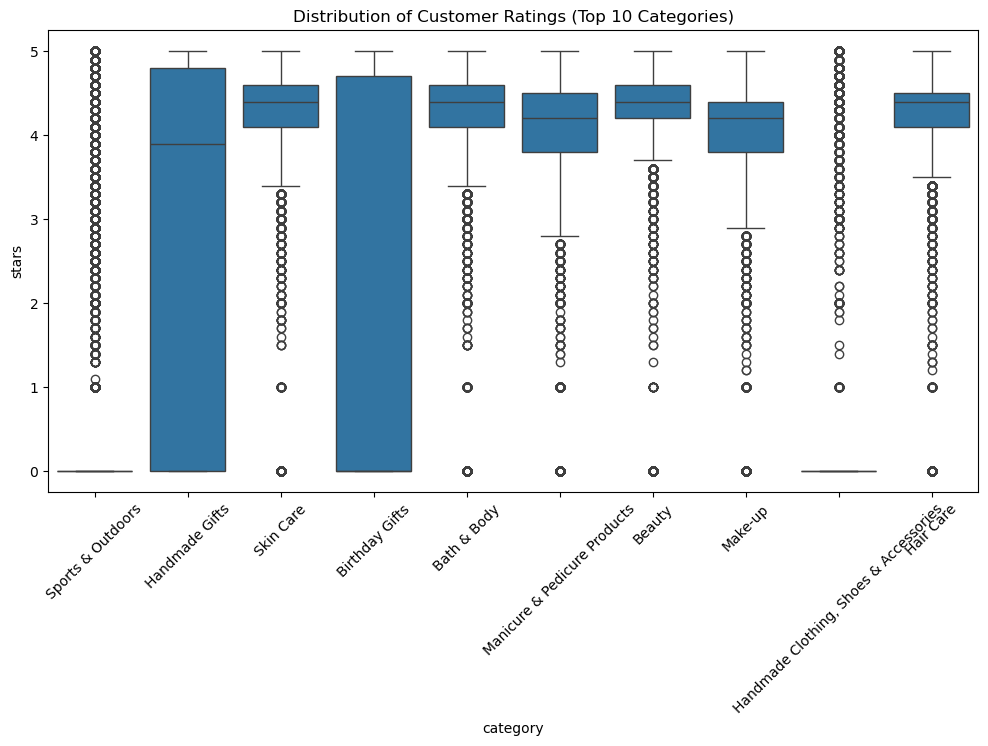

-------
Question: # Which category tends to receive the highest median rating from customers? Don't filter here by top categories.
Category with highest median rating: Computer Memory


In [19]:
# 3. Box Plots:
# Visualize the distribution of product ratings based on their category using side-by-side box plots. Filter out the top 10 categories based on count for better visualization.

top_10_cats_ratings = df_clean['category'].value_counts().nlargest(10).index
df_ratings_top_10 = df_clean[df_clean['category'].isin(top_10_cats_ratings)]

plt.figure(figsize=(12, 6))
sns.boxplot(x='category', y='stars', data=df_ratings_top_10)
plt.xticks(rotation=45)
plt.title('Distribution of Customer Ratings (Top 10 Categories)')
plt.show()


print("-------")
print("Question: # Which category tends to receive the highest median rating from customers? Don't filter here by top categories.")
median_ratings = df_clean.groupby('category')['stars'].median().sort_values(ascending=False)
print(f"Category with highest median rating: {median_ratings.index[0]}")


In [20]:
# ---- Part 3: Investigating the Interplay Between Product Prices and Ratings ---- #

# 1. Correlation Coefficients:
# Calculate the correlation coefficient between price and stars.

correlation = df_clean['price'].corr(df_clean['stars'])

print(f"Correlation between Price and Stars: {correlation:.4f}")

print("-------")
print("QUestion: Is there a significant correlation between product price and its rating?")
print("Answer: there is no significant linear correlation. A higher price does not guarantee a higher rating")

 


Correlation between Price and Stars: -0.0777
-------
QUestion: Is there a significant correlation between product price and its rating?
Answer: there is no significant linear correlation. A higher price does not guarantee a higher rating


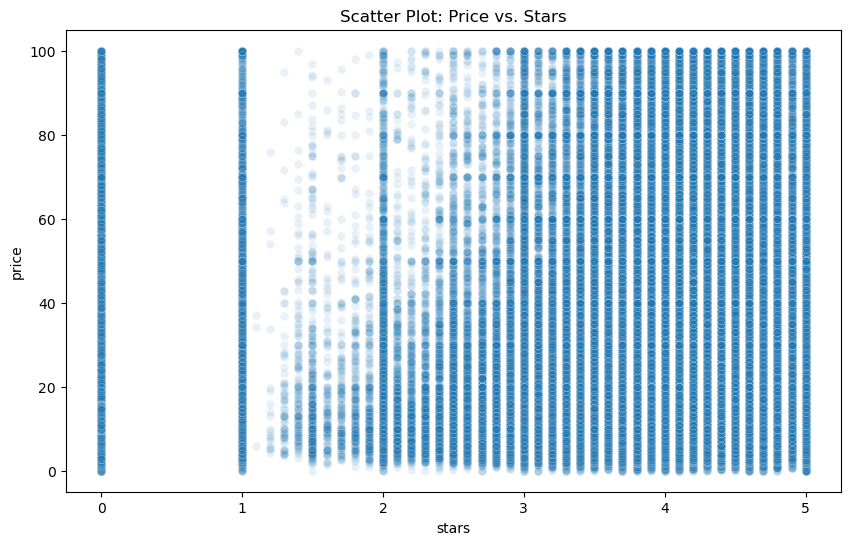

In [21]:
# 2. Visualizations:

# Use a scatter plot to visualize the relationship between product rating and price. What patterns can you observe?

plt.figure(figsize=(10, 6))
sns.scatterplot(x='stars', y='price', data=df_clean, alpha=0.1)
plt.title('Scatter Plot: Price vs. Stars')
plt.show()
       

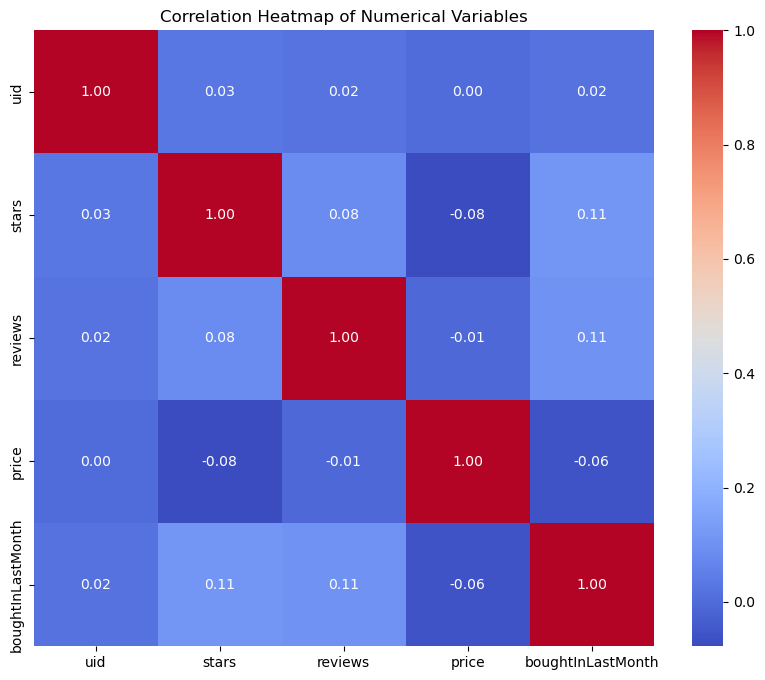

In [22]:
# Use a correlation heatmap to visualize correlations between all numerical variables.

numerical_cols = df_clean.select_dtypes(include=['float64', 'int64'])

plt.figure(figsize=(10, 8))
sns.heatmap(numerical_cols.corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Heatmap of Numerical Variables')
plt.show()

<Figure size 800x600 with 0 Axes>

<Figure size 800x600 with 0 Axes>

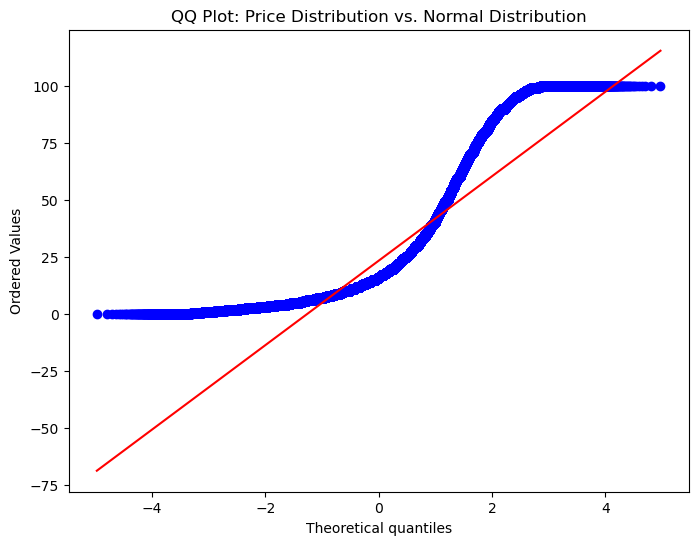

In [27]:
# Examine if product prices typically follow a normal distribution using a QQ plot.

plt.figure(figsize=(8, 6))
stats.probplot(df_clean['price'], dist="norm", plot=plt)
plt.title('QQ Plot: Price Distribution vs. Normal Distribution')
plt.show()
